<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_20_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HEDEF: - Birleşik Krallık(İngiltere) gerçek ulusal elektrik datalarını kullanarak. Gelecek yıllarda seçilen gün ve saatde ne kadar elektirik ihtiyacı olacağını belirlemek. 2024 ve 2025 yılı verilerini kullanacağız.


In [1]:
#Kullanılacak Kaynak 2024 : https://www.neso.energy/data-portal/historic-demand-data/historic_demand_data_2024
#Kullanılacak Kaynak 2025 : https://www.neso.energy/data-portal/historic-demand-data/historic_demand_data_2025

In [3]:
import requests
import pandas as pd

**VERİYİ API ÜZERİNDEN ÇEKMEK **

In [6]:
API = "https://api.neso.energy/api/3/action/datastore_search" # API adresini ve 2 farklı kaynağın id sini değişkene atadım.

kaynak_2024 = "f6d02c0f-957b-48cb-82ee-09003f2ba759"
kaynak_2025 = "b2bde559-3455-4021-b179-dfe60c0337b0"

In [10]:
#DENEME YAPALIM ÇALIŞIYORSA TÜM DATAYI ÇEKECEĞİZ.
cevap = requests.get(API, params={"resource_id": kaynak_2024, "limit":1},timeout=60) # params adresin sonuna eklenecek parametreler. limit: deneme için sadece 1 adet getirmesi için. timeout: sunucu 60 saniyre ecvap vermezse duracak.
print(cevap.status_code) #servisin bize döneceği kod. 200 dönerse istek başarılı demek.

json_veri = cevap.json()
print(json_veri["result"]["total"]) # tablodaki satır sayısı.
print(json_veri["result"]["records"][0]) # ilk satır.

200
17568
{'_id': 1, 'SETTLEMENT_DATE': '2024-01-01', 'SETTLEMENT_PERIOD': 1, 'ND': 21783, 'TSD': 23466, 'ENGLAND_WALES_DEMAND': 19539, 'EMBEDDED_WIND_GENERATION': 2804, 'EMBEDDED_WIND_CAPACITY': 6488, 'EMBEDDED_SOLAR_GENERATION': 0, 'EMBEDDED_SOLAR_CAPACITY': 16793, 'NON_BM_STOR': 0, 'PUMP_STORAGE_PUMPING': 808, 'SCOTTISH_TRANSFER': -71, 'IFA_FLOW': 417, 'IFA2_FLOW': -4, 'BRITNED_FLOW': 666, 'MOYLE_FLOW': -179, 'EAST_WEST_FLOW': -92, 'NEMO_FLOW': 905, 'NSL_FLOW': 62, 'ELECLINK_FLOW': 998, 'VIKING_FLOW': 572, 'GREENLINK_FLOW': 0}


In [12]:
cevap = requests.get(API, params={"resource_id": kaynak_2024, "limit":20000},timeout=60)
df_2024 = pd.DataFrame(cevap.json()["result"]["records"])
print("2024 yılı ",df_2024.shape)

2024 yılı  (17568, 23)


In [14]:
cevap = requests.get(API, params={"resource_id": kaynak_2025, "limit":20000},timeout=60)
df_2025 = pd.DataFrame(cevap.json()["result"]["records"])
print("2025 yılı ",df_2025.shape)

2025 yılı  (17520, 23)


In [16]:
talep = pd.concat([df_2024,df_2025], ignore_index=True)
talep.to_csv("elektrik_ham.csv", index=False)
print("Toplam:",talep.shape)

Toplam: (35088, 23)


VERİ ANALİZİ - VERİYİ TANIMA VE TEMİZLEME

In [18]:
import numpy as np
import matplotlib.pyplot as plt

In [21]:
talep = pd.read_csv("/content/elektrik_ham.csv")
talep.shape

(35088, 23)

In [23]:
talep.head()

,_id,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,1,2024-01-01,1,21783,23466,19539,2804,6488,0,16793,...,417,-4,666,-179,-92,905,62,998,572,0
1,2,2024-01-01,2,22521,24103,20286,2834,6488,0,16793,...,430,-4,661,-60,-8,901,-15,998,575,0
2,3,2024-01-01,3,22194,24754,20070,2868,6488,0,16793,...,834,-4,661,-118,-1,807,-396,997,422,0
3,4,2024-01-01,4,21510,24505,19424,2901,6488,0,16793,...,839,-4,661,-270,-84,803,-473,997,401,0
4,5,2024-01-01,5,20619,23977,18674,2933,6488,0,16793,...,53,-5,661,-340,-103,537,-856,998,28,0


In [26]:
talep = talep[["SETTLEMENT_DATE","SETTLEMENT_PERIOD","ND"]]
talep.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND
0,2024-01-01,1,21783
1,2024-01-01,2,22521
2,2024-01-01,3,22194
3,2024-01-01,4,21510
4,2024-01-01,5,20619


In [28]:
talep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35088 entries, 0 to 35087
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   SETTLEMENT_DATE    35088 non-null  object
 1   SETTLEMENT_PERIOD  35088 non-null  int64 
 2   ND                 35088 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 822.5+ KB


In [30]:
dilim_sayisi = talep.groupby("SETTLEMENT_DATE").size() # kaç satır var onu sayacak. tarihlerin aralığına bakıyoruz.
dilim_sayisi.value_counts()


,count
48,727
46,2
50,2


In [34]:
talep = talep[talep["SETTLEMENT_PERIOD"] <= 48] #aykırıları çıkardık.

talep["saat"] = (talep["SETTLEMENT_PERIOD"] - 1) // 2 # datamızda her yarım saatlik dilim 1 periyottu. Biz bunu saat sütudunda tam sayı olarak vermeye çalıştık.

print(talep[["SETTLEMENT_PERIOD", "saat"]].head(8))



   SETTLEMENT_PERIOD  saat
0                  1     0
1                  2     0
2                  3     1
3                  4     1
4                  5     2
5                  6     2
6                  7     3
7                  8     3


In [42]:
veri = talep.groupby(["SETTLEMENT_DATE","saat"])["ND"].mean().reset_index()
print(veri.shape)
print(veri.head(30))

(17542, 3)
   SETTLEMENT_DATE  saat       ND
0       2024-01-01     0  22152.0
1       2024-01-01     1  21852.0
2       2024-01-01     2  20359.0
3       2024-01-01     3  19044.0
4       2024-01-01     4  18246.5
5       2024-01-01     5  18134.0
6       2024-01-01     6  19067.0
7       2024-01-01     7  20156.0
8       2024-01-01     8  21832.0
9       2024-01-01     9  23460.5
10      2024-01-01    10  24667.5
11      2024-01-01    11  26305.5
12      2024-01-01    12  28300.0
13      2024-01-01    13  29722.0
14      2024-01-01    14  30673.0
15      2024-01-01    15  32125.5
16      2024-01-01    16  34289.5
17      2024-01-01    17  34662.0
18      2024-01-01    18  33166.0
19      2024-01-01    19  31099.5
20      2024-01-01    20  28283.5
21      2024-01-01    21  25530.5
22      2024-01-01    22  22923.5
23      2024-01-01    23  20433.5
24      2024-01-02     0  20223.5
25      2024-01-02     1  19702.5
26      2024-01-02     2  19110.0
27      2024-01-02     3  18589.5
28 

In [45]:
veri.columns = ["tarih", "saat", "talep"]
veri.head()

,tarih,saat,talep
0,2024-01-01,0,22152.0
1,2024-01-01,1,21852.0
2,2024-01-01,2,20359.0
3,2024-01-01,3,19044.0
4,2024-01-01,4,18246.5


In [50]:
# Formatlar ve Özellik Üretimi

veri["tarih"] = pd.to_datetime(veri["tarih"])
veri["gun"] = veri["tarih"].dt.dayofweek #tarih formatındaki sütundan yeni satır oluşturuyoruz. Haftanın günleri oluşacak. 0=pazartesi, 1= salı ...
veri["ay"] = veri["tarih"].dt.month # tarih formatındaki sutundan ay sütunu türetiyoruz. Ay bazlı değerlendirebilmek için. (saat gün ve ay elimizde artık)

veri.head(50)

,tarih,saat,talep,gun,ay
0,2024-01-01,0,22152.0,0,1
1,2024-01-01,1,21852.0,0,1
2,2024-01-01,2,20359.0,0,1
3,2024-01-01,3,19044.0,0,1
4,2024-01-01,4,18246.5,0,1
5,2024-01-01,5,18134.0,0,1
6,2024-01-01,6,19067.0,0,1
7,2024-01-01,7,20156.0,0,1
8,2024-01-01,8,21832.0,0,1
9,2024-01-01,9,23460.5,0,1


**KEŞİFÇİ VERİ ANALİZİ (EDA)**

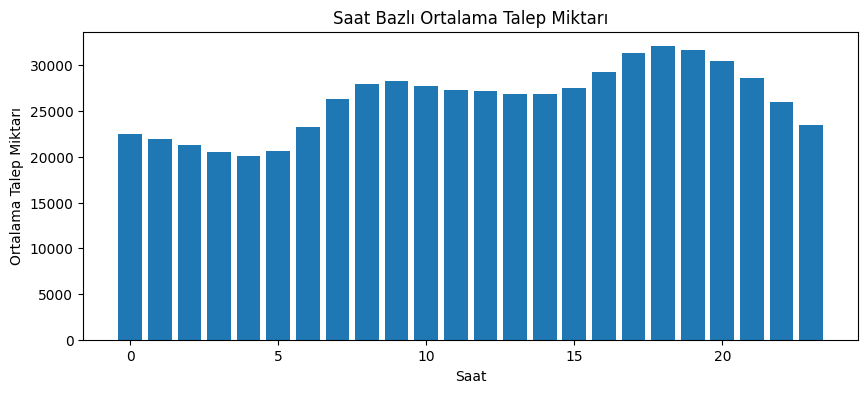

In [52]:
saat_ort = veri.groupby("saat")["talep"].mean()

plt.figure(figsize=(10,4))
plt.bar(saat_ort.index, saat_ort.values)
plt.xlabel("Saat")
plt.ylabel("Ortalama Talep Miktarı")
plt.title("Saat Bazlı Ortalama Talep Miktarı")
plt.show()

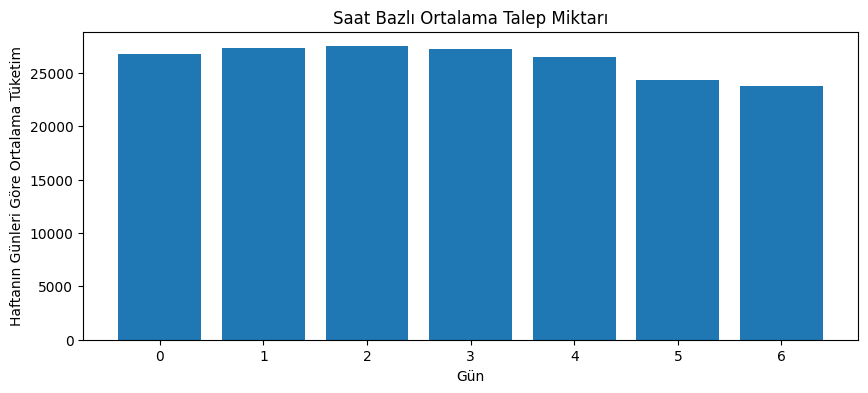

In [55]:
# gün ortalaması alın. hangi günlerde tüketim fazla bunu grafikleştir. bar.
gun_ort = veri.groupby("gun")["talep"].mean()

plt.figure(figsize=(10,4))
plt.bar(gun_ort.index, gun_ort.values)
plt.xlabel("Gün")
plt.ylabel("Haftanın Günleri Göre Ortalama Tüketim")
plt.title("Saat Bazlı Ortalama Talep Miktarı")
plt.show()